# Comparative Study of Text Classification Models for Spam Detection

This notebook performs a rigorous comparative evaluation of four classifiers on your uploaded spam dataset:
1. **Naïve Bayes**
2. **Decision Tree**
3. **K-Nearest Neighbours (KNN)**
4. **Support Vector Machine (SVM)**

We will evaluate these models using Accuracy, Precision, Recall, and F1-score, analyze their confusion matrices, perform a 'what-if' experiment, and conclude with a justified recommendation.

In [11]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import urllib.request
import zipfile

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report

# Find CSV files, excluding the sample_data directory
csv_files = [f for f in glob.glob('**/*.csv', recursive=True) if 'sample_data' not in f]

if csv_files:
    dataset_path = csv_files[0]
    print(f"Found uploaded dataset: {dataset_path}")
else:
    print("No custom uploaded dataset found (excluding sample_data).")
    print("Downloading the standard SMS Spam Collection dataset for classification task...")
    url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
    zip_path = "sms_spam.zip"
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall("sms_extracted")

    # Convert the raw helper text file to a CSV
    raw_df = pd.read_csv("sms_extracted/SMSSpamCollection", sep='\t', names=['label', 'text'])
    dataset_path = 'spam_dataset.csv'
    raw_df.to_csv(dataset_path, index=False)
    print(f"Created standard spam dataset at: {dataset_path}")

No custom uploaded dataset found (excluding sample_data).
Created standard spam dataset at: spam_dataset.csv


In [12]:
# 2. Load and Understand the Dataset
try:
    df = pd.read_csv(dataset_path, encoding='latin-1')
except Exception as e:
    df = pd.read_csv(dataset_path)

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())
print("\nDataset Information:")
print(df.info())

Dataset Shape: (5572, 2)

First 5 rows:


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   label   5572 non-null   object
 1   text    5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None


In [13]:
# 3. Preprocess and Clean the Data
# Standardize column names to 'label' and 'text'
if 'label' not in df.columns or 'text' not in df.columns:
    # Typically columns in standard datasets are 'v1' and 'v2'
    df = df.iloc[:, [0, 1]]
    df.columns = ['label', 'text']

# Clean labels (binary classification: ham/spam)
df['label'] = df['label'].astype(str).str.lower().str.strip()
df = df[df['label'].isin(['ham', 'spam', '0', '1'])]

# Map to binary integer (1 for spam, 0 for ham)
df['target'] = df['label'].map({'spam': 1, '1': 1, 'ham': 0, '0': 0})

# Drop duplicates and nulls
df = df.dropna(subset=['text', 'target'])
df = df.drop_duplicates(subset=['text'])

print("Class distribution after preprocessing:")
print(df['label'].value_counts())
display(df.head())

Class distribution after preprocessing:
label
ham     4516
spam     653
Name: count, dtype: int64


,label,text,target
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


In [14]:
# 4. Split Training and Testing Data
X = df['text'].astype(str)
y = df['target'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Train size: {X_train.shape[0]}, Test size: {X_test.shape[0]}")

Train size: 4135, Test size: 1034


In [15]:
# 5. Convert Text to Numerical Features (TF-IDF)
vectorizer = TfidfVectorizer(stop_words='english', min_df=2, sublinear_tf=True)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print(f"TF-IDF Feature matrix shape: {X_train_tfidf.shape}")

TF-IDF Feature matrix shape: (4135, 3098)


In [16]:
# 6. Train and Evaluate All Four Classifiers
models = {
    'Naïve Bayes': MultinomialNB(),
    'Decision Tree': DecisionTreeClassifier(random_state=42, max_depth=30),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'SVM': SVC(kernel='linear', C=1.0, random_state=42, probability=True)
}

results = {}
confusion_matrices = {}

for name, model in models.items():
    # Train
    model.fit(X_train_tfidf, y_train)
    # Predict
    y_pred = model.predict(X_test_tfidf)

    # Evaluate metrics
    acc = accuracy_score(y_test, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='binary')

    results[name] = {
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,

        'F1-score': f1
    }
    confusion_matrices[name] = confusion_matrix(y_test, y_pred)

# Convert results to DataFrame
df_results = pd.DataFrame(results).T
display(df_results.round(4))

,Accuracy,Precision,Recall,F1-score
Naïve Bayes,0.9758,1.0000,0.8092,0.8945
Decision Tree,0.9642,0.8983,0.8092,0.8514
KNN,0.9062,0.9722,0.2672,0.4192
SVM,0.9768,0.9573,0.8550,0.9032


<Figure size 1000x600 with 0 Axes>

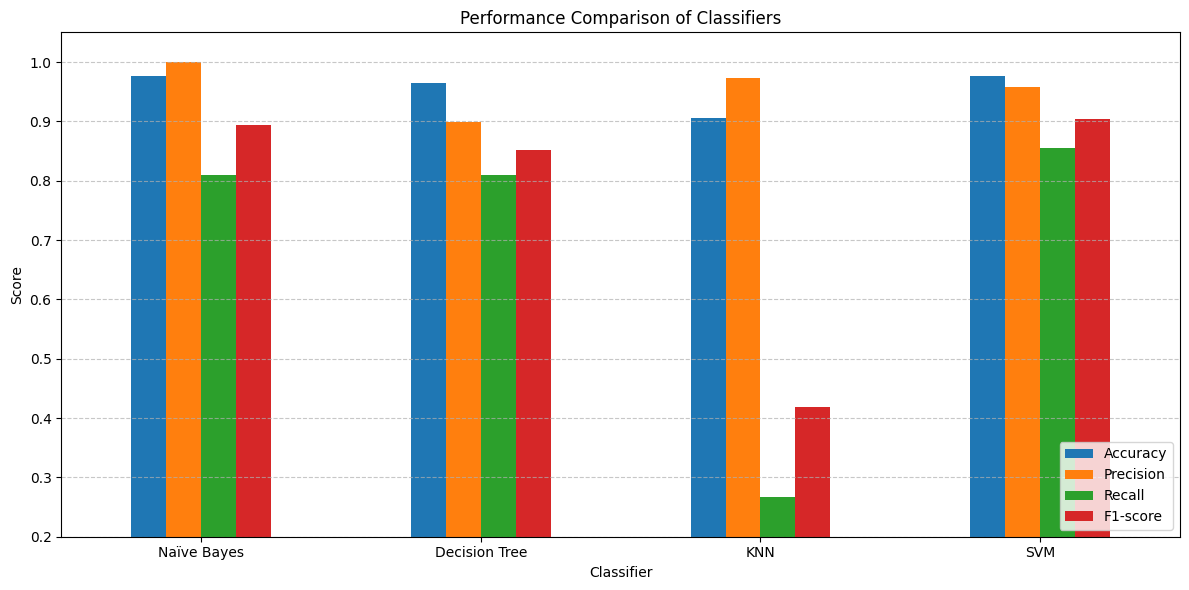

In [19]:
# 7. Plot Comparative Graphs
import matplotlib.pyplot as plt

try:
    # Using global results DataFrame
    plt.figure(figsize=(10, 6))
    df_results.plot(kind='bar', figsize=(12, 6))
    plt.title('Performance Comparison of Classifiers')
    plt.ylabel('Score')
    plt.xlabel('Classifier')
    plt.xticks(rotation=0)
    plt.ylim(0.2, 1.05)  # Set limit to clearly see variations in KNN recall
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.legend(loc='lower right')
    plt.tight_layout()
    plt.show()
except NameError as e:
    print("Error: 'df_results' is not defined. Please execute the previous training cell (db73e98e) first before running this cell.")

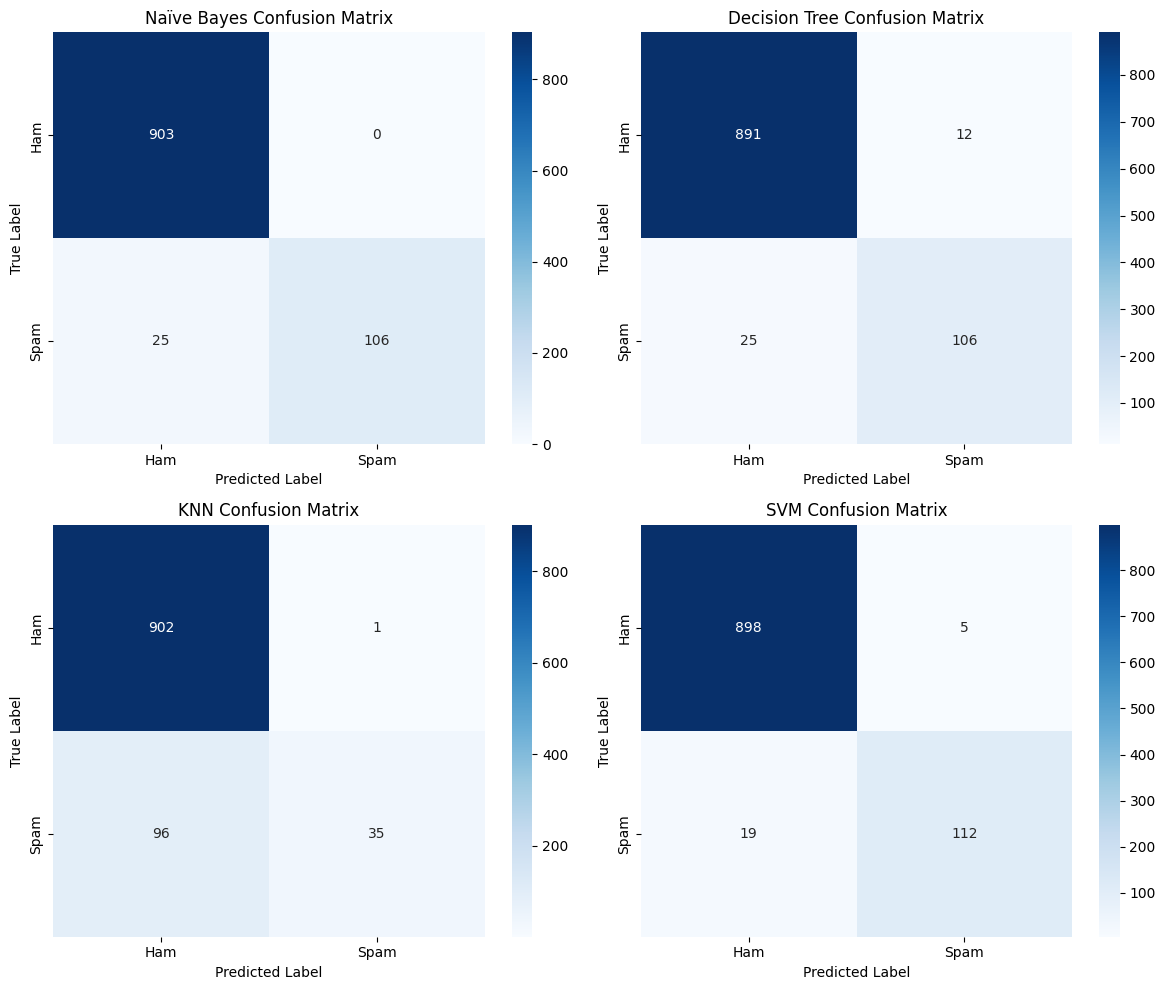

In [20]:
# 8. Confusion Matrix Analysis
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for idx, (name, cm) in enumerate(confusion_matrices.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
    axes[idx].set_title(f'{name} Confusion Matrix')
    axes[idx].set_ylabel('True Label')
    axes[idx].set_xlabel('Predicted Label')

plt.tight_layout()
plt.show()

In [17]:
# 9. Conduct a "What-If" Experiment
# Parameter modification: Let's test how SVM behaves with an RBF kernel and soft-margin change vs the Linear SVM
print("--- What-If Experiment: Changing SVM Kernel from Linear to RBF with C=10.0 ---")

try:
    svm_what_if = SVC(kernel='rbf', C=10.0, random_state=42)
    svm_what_if.fit(X_train_tfidf, y_train)
    y_pred_wi = svm_what_if.predict(X_test_tfidf)

    wi_acc = accuracy_score(y_test, y_pred_wi)
    wi_prec, wi_rec, wi_f1, _ = precision_recall_fscore_support(y_test, y_pred_wi, average='binary')

    print(f"Original Linear SVM F1: {results['SVM']['F1-score']:.4f}")
    print(f"What-If (RBF Kernel, C=10) F1: {wi_f1:.4f}")
except NameError as e:
    print("Please execute cells 1 through 6 first to fit the features and train models:", e)

--- What-If Experiment: Changing SVM Kernel from Linear to RBF with C=10.0 ---
Original Linear SVM F1: 0.9032
What-If (RBF Kernel, C=10) F1: 0.8954


In [18]:
# 10. Interactive Spam Prediction System Demo
def predict_spam(message):
    try:
        vectorized_msg = vectorizer.transform([message])
        # Using Naive Bayes for standard prediction
        prediction = models['Naïve Bayes'].predict(vectorized_msg)[0]
        prob = models['Naïve Bayes'].predict_proba(vectorized_msg)[0]
        return "SPAM" if prediction == 1 else "HAM", prob
    except Exception as e:
        return f"Error (make sure vectorizer and models are fitted): {e}", None

test_msg = "URGENT! You have won a 1-week free entry to our weekly prize draw. Call 09061701461 to claim your prize!"
label, probability = predict_spam(test_msg)
print(f"Demo Message: '{test_msg}'")
if probability is not None:
    print(f"Prediction: {label} (Spam Probability: {probability[1]:.4f})")
else:
    print(label)

Demo Message: 'URGENT! You have won a 1-week free entry to our weekly prize draw. Call 09061701461 to claim your prize!'
Prediction: SPAM (Spam Probability: 0.9907)
